# FRB LSTM Classifier — 2

**Input:** `lstm_dataset_v6.npz` from the augmentation pipeline

**Goal:** Binary classifier (FRB vs noise) that:
- Processes streaming time-frequency data
- Outputs P(FRB) at each timestep
- Is small enough for FPGA synthesis via hls4ml

**FPGA constraints:**
- < 50k total parameters
- Flatten dimension < 500 neurons
- Prefer small LSTM hidden sizes (16–32)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
from datetime import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    roc_curve, auc, precision_recall_curve
)

print(f"TensorFlow: {tf.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.20.0
GPUs: []


In [2]:
# ============================================================
# ALL CONFIGURATION IN ONE PLACE
# ============================================================

CONFIG = {
    # --- Data ---
    "data_path": "./augmented_dataset/lstm_dataset_v6.npz",
    
    # --- Model Architecture ---
    "model_type": "lstm",          # "lstm", "bilstm", "gru"
    "n_rnn_layers": 1,             # number of stacked RNN layers
    "rnn_units": 32,               # hidden units per RNN layer (FPGA: keep 16-64)
    "rnn_dropout": 0.0,            # recurrent dropout (set 0 for FPGA compatibility)
    "use_layernorm": False,        # layer normalization after RNN
    
    "dense_units": [32],           # dense layers after RNN (list, can be empty [])
    "dense_dropout": 0.3,          # dropout between dense layers
    "dense_activation": "relu",    # activation for dense layers
    
    "return_sequences": False,     # True = P(FRB) at every timestep, False = single output
    
    # --- Feature Reduction (optional, before RNN) ---
    # Reduces 256 freq channels to fewer features per timestep
    # Helps with FPGA size. Set to None to skip.
    "freq_reduction": 64,        # None, or int (e.g. 64, 32) for a Dense reduction layer
    
    # --- Training ---
    "batch_size": 128,
    "epochs": 150,
    "learning_rate": 1e-3,
    "optimizer": "adam",           # "adam", "sgd", "adamw"
    "lr_schedule": "reduce_on_plateau",  # "reduce_on_plateau", "cosine", "none"
    "lr_patience": 5,              # for reduce_on_plateau
    "lr_factor": 0.5,              # for reduce_on_plateau
    "early_stop_patience": 10,
    "class_weight": "auto",        # "auto", "none", or dict like {0: 1.0, 1: 2.0}
    
    # --- Output ---
    "save_dir": "./models/",
    "experiment_name": "lstm_v3",
}

# Print config
print("Configuration:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuration:
  data_path: ./augmented_dataset/lstm_dataset_v6.npz
  model_type: lstm
  n_rnn_layers: 1
  rnn_units: 32
  rnn_dropout: 0.0
  use_layernorm: False
  dense_units: [32]
  dense_dropout: 0.3
  dense_activation: relu
  return_sequences: False
  freq_reduction: 64
  batch_size: 128
  epochs: 150
  learning_rate: 0.001
  optimizer: adam
  lr_schedule: reduce_on_plateau
  lr_patience: 5
  lr_factor: 0.5
  early_stop_patience: 10
  class_weight: auto
  save_dir: ./models/
  experiment_name: lstm_v3


## 1. Load Data

In [3]:
data = np.load(CONFIG["data_path"])
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

n_timesteps = X_train.shape[1]
n_features = X_train.shape[2]

print(f"Train: {X_train.shape} — {np.mean(y_train):.1%} FRB")
print(f"Val:   {X_val.shape} — {np.mean(y_val):.1%} FRB")
print(f"Test:  {X_test.shape} — {np.mean(y_test):.1%} FRB")
print(f"\nInput shape: ({n_timesteps} timesteps, {n_features} features)")

Train: (1436, 256, 256) — 50.0% FRB
Val:   (308, 256, 256) — 50.0% FRB
Test:  (308, 256, 256) — 50.0% FRB

Input shape: (256 timesteps, 256 features)


## 2. Build Model

In [4]:
def build_model(config, n_timesteps, n_features):
    """
    Build RNN model from config dict.
    Supports LSTM, BiLSTM, GRU with configurable depth, width, and regularization.
    """
    inputs = keras.Input(shape=(n_timesteps, n_features), name="input")
    x = inputs
    
    # --- Optional frequency reduction ---
    if config["freq_reduction"] is not None:
        x = layers.Conv1D(config["freq_reduction"], kernel_size=1, 
                                activation="relu", name="freq_reduce")(x)
    
    # --- RNN layers ---
    rnn_class_map = {
        "lstm": layers.LSTM,
        "gru": layers.GRU,
        "bilstm": None,  # handled separately
    }
    
    n_layers = config["n_rnn_layers"]
    units = config["rnn_units"]
    return_seq = config["return_sequences"]
    
    for i in range(n_layers):
        # Last layer: return_sequences based on config
        # Earlier layers: always return sequences (to stack)
        ret_seq = True if i < n_layers - 1 else return_seq
        
        rnn_kwargs = {
            "units": units,
            "return_sequences": ret_seq,
            "recurrent_dropout": config["rnn_dropout"],
            "name": f"rnn_{i}",
        }
        
        if config["model_type"] == "bilstm":
            rnn_layer = layers.Bidirectional(
                layers.LSTM(**rnn_kwargs), name=f"birnn_{i}"
            )
        elif config["model_type"] == "gru":
            rnn_layer = layers.GRU(**rnn_kwargs)
        else:  # lstm
            rnn_layer = layers.LSTM(**rnn_kwargs)
        
        x = rnn_layer(x)
    
    # --- Layer norm ---
    if config["use_layernorm"]:
        x = layers.LayerNormalization(name="layernorm")(x)
    
    # --- Dense head ---
    # If return_sequences=True, apply Dense via TimeDistributed
    for j, dense_units in enumerate(config["dense_units"]):
        if return_seq:
            x = layers.TimeDistributed(
                layers.Dense(dense_units, activation=config["dense_activation"]),
                name=f"dense_{j}"
            )(x)
        else:
            x = layers.Dense(dense_units, activation=config["dense_activation"],
                             name=f"dense_{j}")(x)
        
        if config["dense_dropout"] > 0:
            x = layers.Dropout(config["dense_dropout"], name=f"drop_{j}")(x)
    
    # --- Output ---
    if return_seq:
        outputs = layers.TimeDistributed(
            layers.Dense(1, activation="sigmoid"), name="output"
        )(x)
    else:
        outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [5]:
model = build_model(CONFIG, n_timesteps, n_features)
model.summary()

# Count parameters
total_params = model.count_params()
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)

print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

if total_params > 50000:
    print(f"⚠️  Exceeds 50k FPGA parameter budget! Reduce rnn_units or dense_units.")
else:
    print(f"✅ Within 50k FPGA parameter budget.")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 256, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ freq_reduce (Conv1D)            │ (None, 256, 64)        │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn_0 (LSTM)                    │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,953 (117.00 KB)

 Trainable params: 29,953 (117.00 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters:     29,953
Trainable parameters: 29,953
✅ Within 50k FPGA parameter budget.


## 3. Compile & Configure Training

In [6]:
# Optimizer
opt_map = {
    "adam": optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
    "adamw": optimizers.AdamW(learning_rate=CONFIG["learning_rate"]),
    "sgd": optimizers.SGD(learning_rate=CONFIG["learning_rate"], momentum=0.9),
}
optimizer = opt_map[CONFIG["optimizer"]]

# For return_sequences=True, labels need to be broadcast across timesteps
if CONFIG["return_sequences"]:
    y_train_model = np.repeat(y_train[:, np.newaxis, np.newaxis], n_timesteps, axis=1)
    y_val_model = np.repeat(y_val[:, np.newaxis, np.newaxis], n_timesteps, axis=1)
    y_test_model = np.repeat(y_test[:, np.newaxis, np.newaxis], n_timesteps, axis=1)
else:
    y_train_model = y_train
    y_val_model = y_val
    y_test_model = y_test

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Class weights
if CONFIG["class_weight"] == "auto":
    n_pos = np.sum(y_train == 1)
    n_neg = np.sum(y_train == 0)
    class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
    print(f"Auto class weights: {class_weight}")
elif CONFIG["class_weight"] == "none":
    class_weight = None
else:
    class_weight = CONFIG["class_weight"]

# Callbacks
save_dir = os.path.join(CONFIG["save_dir"], CONFIG["experiment_name"])
os.makedirs(save_dir, exist_ok=True)

cb_list = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=CONFIG["early_stop_patience"],
        restore_best_weights=True,
        verbose=1,
    ),
    callbacks.ModelCheckpoint(
        os.path.join(save_dir, "best_model.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
]

if CONFIG["lr_schedule"] == "reduce_on_plateau":
    cb_list.append(callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=CONFIG["lr_factor"],
        patience=CONFIG["lr_patience"],
        min_lr=1e-6,
        verbose=1,
    ))
elif CONFIG["lr_schedule"] == "cosine":
    steps_per_epoch = len(X_train) // CONFIG["batch_size"]
    total_steps = steps_per_epoch * CONFIG["epochs"]
    cb_list.append(callbacks.LearningRateScheduler(
        lambda epoch: CONFIG["learning_rate"] * 0.5 * (
            1 + np.cos(np.pi * epoch / CONFIG["epochs"])
        )
    ))

print(f"\nCallbacks: {[type(cb).__name__ for cb in cb_list]}")
print(f"Save directory: {save_dir}")

Auto class weights: {0: 1.0, 1: 1.0}

Callbacks: ['EarlyStopping', 'ModelCheckpoint', 'ReduceLROnPlateau']
Save directory: ./models/lstm_v3


## 4. Train

In [7]:
history = model.fit(
    X_train, y_train_model,
    validation_data=(X_val, y_val_model),
    epochs=CONFIG["epochs"],
    batch_size=CONFIG["batch_size"],
    class_weight=class_weight,
    callbacks=cb_list,
    verbose=1,
)

Epoch 1/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - accuracy: 0.4965 - loss: 0.7093 - val_accuracy: 0.4935 - val_loss: 0.6962 - learning_rate: 0.0010
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5230 - loss: 0.6973 - val_accuracy: 0.5130 - val_loss: 0.6933 - learning_rate: 0.0010
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.5292 - loss: 0.6928 - val_accuracy: 0.5649 - val_loss: 0.6890 - learning_rate: 0.0010
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.5474 - loss: 0.6876 - val_accuracy: 0.5779 - val_loss: 0.6884 - learning_rate: 0.0010
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5279 - loss: 0.6929 - val_accuracy: 0.4870 - val_loss: 0.6902 - learning_rate: 0.0010
Epoch 6/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5397 - loss: 0.6922 - val_accuracy: 0.5812 - val_loss: 0.6899 - learning_rate: 0.0010
Epoch 7/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5522 - loss: 0.6850 - 

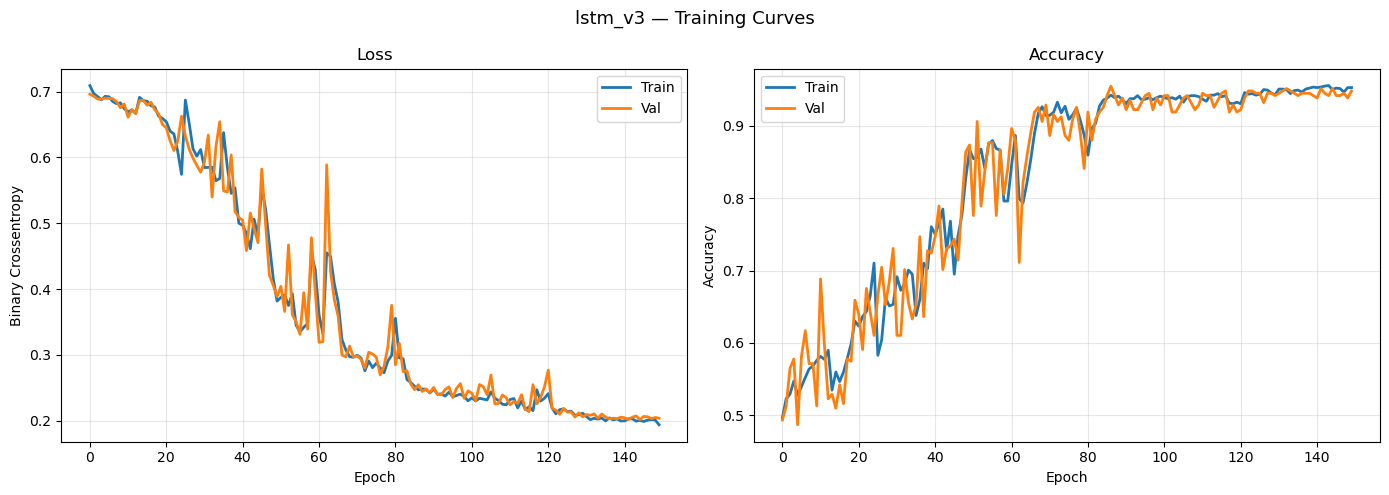


Best epoch: 145
  Train loss: 0.2002, acc: 0.9499
  Val loss:   0.2015, acc: 0.9513


In [8]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"], label="Train", linewidth=2)
axes[0].plot(history.history["val_loss"], label="Val", linewidth=2)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Train", linewidth=2)
axes[1].plot(history.history["val_accuracy"], label="Val", linewidth=2)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"{CONFIG['experiment_name']} — Training Curves", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "training_curves.png"), dpi=150)
plt.show()

best_epoch = np.argmin(history.history["val_loss"])
print(f"\nBest epoch: {best_epoch + 1}")
print(f"  Train loss: {history.history['loss'][best_epoch]:.4f}, "
      f"acc: {history.history['accuracy'][best_epoch]:.4f}")
print(f"  Val loss:   {history.history['val_loss'][best_epoch]:.4f}, "
      f"acc: {history.history['val_accuracy'][best_epoch]:.4f}")

## 5. Evaluate on Test Set

In [9]:
# Predict
y_pred_prob = model.predict(X_test, batch_size=CONFIG["batch_size"]).flatten()

# If return_sequences, take the prediction from the last timestep
if CONFIG["return_sequences"]:
    y_pred_prob = y_pred_prob[:, -1, 0]  # last timestep prediction

y_pred = (y_pred_prob >= 0.5).astype(int)

# Metrics
test_loss, test_acc = model.evaluate(X_test, y_test_model, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"\n{classification_report(y_test, y_pred, target_names=['Noise', 'FRB'])}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Test Loss:     0.1765
Test Accuracy: 0.9643

              precision    recall  f1-score   support

       Noise       0.93      1.00      0.97       154
         FRB       1.00      0.93      0.96       154

    accuracy                           0.96       308
   macro avg       0.97      0.96      0.96       308
weighted avg       0.97      0.96      0.96       308



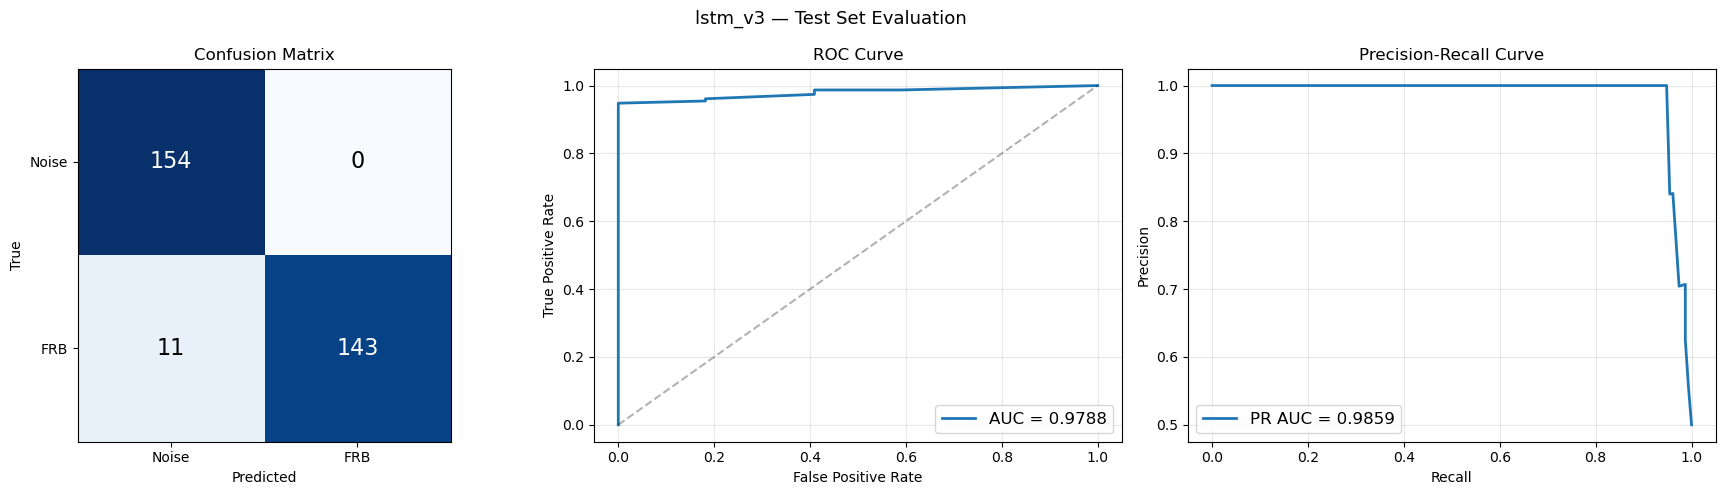

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Noise", "FRB"])
axes[0].set_yticklabels(["Noise", "FRB"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i,j]}", ha='center', va='center', fontsize=16,
                     color='white' if cm[i,j] > cm.max()/2 else 'black')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.4f}")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

# Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
pr_auc = auc(recall, precision)
axes[2].plot(recall, precision, linewidth=2, label=f"PR AUC = {pr_auc:.4f}")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend(fontsize=12)
axes[2].grid(True, alpha=0.3)

plt.suptitle(f"{CONFIG['experiment_name']} — Test Set Evaluation", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "evaluation.png"), dpi=150)
plt.show()

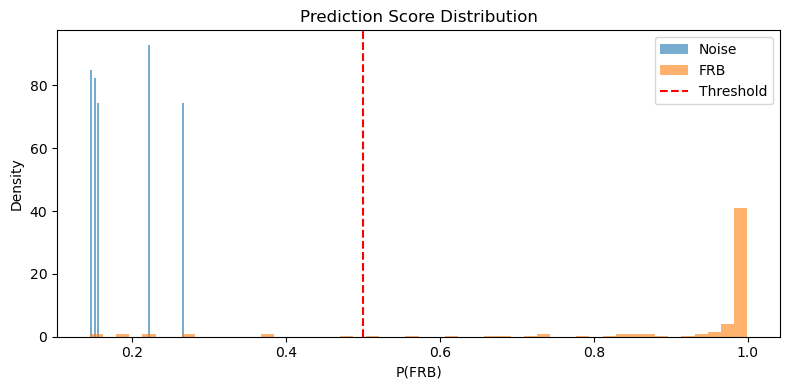

Median P(FRB) for actual FRBs:  0.9905
Median P(FRB) for actual noise: 0.1563
Separation: 0.8342


In [11]:
# Prediction distribution
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(y_pred_prob[y_test == 0], bins=50, alpha=0.6, label="Noise", density=True)
ax.hist(y_pred_prob[y_test == 1], bins=50, alpha=0.6, label="FRB", density=True)
ax.axvline(0.5, color='r', ls='--', label="Threshold")
ax.set_xlabel("P(FRB)")
ax.set_ylabel("Density")
ax.set_title("Prediction Score Distribution")
ax.legend()

plt.tight_layout()
plt.show()

# Separation quality
frb_median = np.median(y_pred_prob[y_test == 1])
noise_median = np.median(y_pred_prob[y_test == 0])
print(f"Median P(FRB) for actual FRBs:  {frb_median:.4f}")
print(f"Median P(FRB) for actual noise: {noise_median:.4f}")
print(f"Separation: {frb_median - noise_median:.4f}")

## 6. Streaming Simulation: P(FRB) Over Time

Simulate feeding data timestep-by-timestep and watching P(FRB) evolve.
This mimics the real-time FPGA scenario.

In [12]:
def streaming_prediction(model, sample, step_size=1):
    """
    Feed progressively longer prefixes of the sample to the model.
    Returns P(FRB) at each timestep.
    
    For return_sequences=False models, pads with zeros to maintain input shape.
    For return_sequences=True models, uses native per-timestep output.
    """
    n_timesteps, n_features = sample.shape
    probs = []
    
    if CONFIG["return_sequences"]:
        # Single forward pass, get all timestep predictions
        pred = model.predict(sample[np.newaxis, :, :], verbose=0)
        probs = pred[0, :, 0].tolist()
    else:
        # Feed progressively longer windows
        for t in range(step_size, n_timesteps + 1, step_size):
            # Zero-pad the front so shape stays (n_timesteps, n_features)
            padded = np.zeros((n_timesteps, n_features), dtype=np.float32)
            padded[n_timesteps - t:, :] = sample[:t, :]
            pred = model.predict(padded[np.newaxis, :, :], verbose=0)
            probs.append(float(pred[0, 0]))
    
    return np.array(probs)

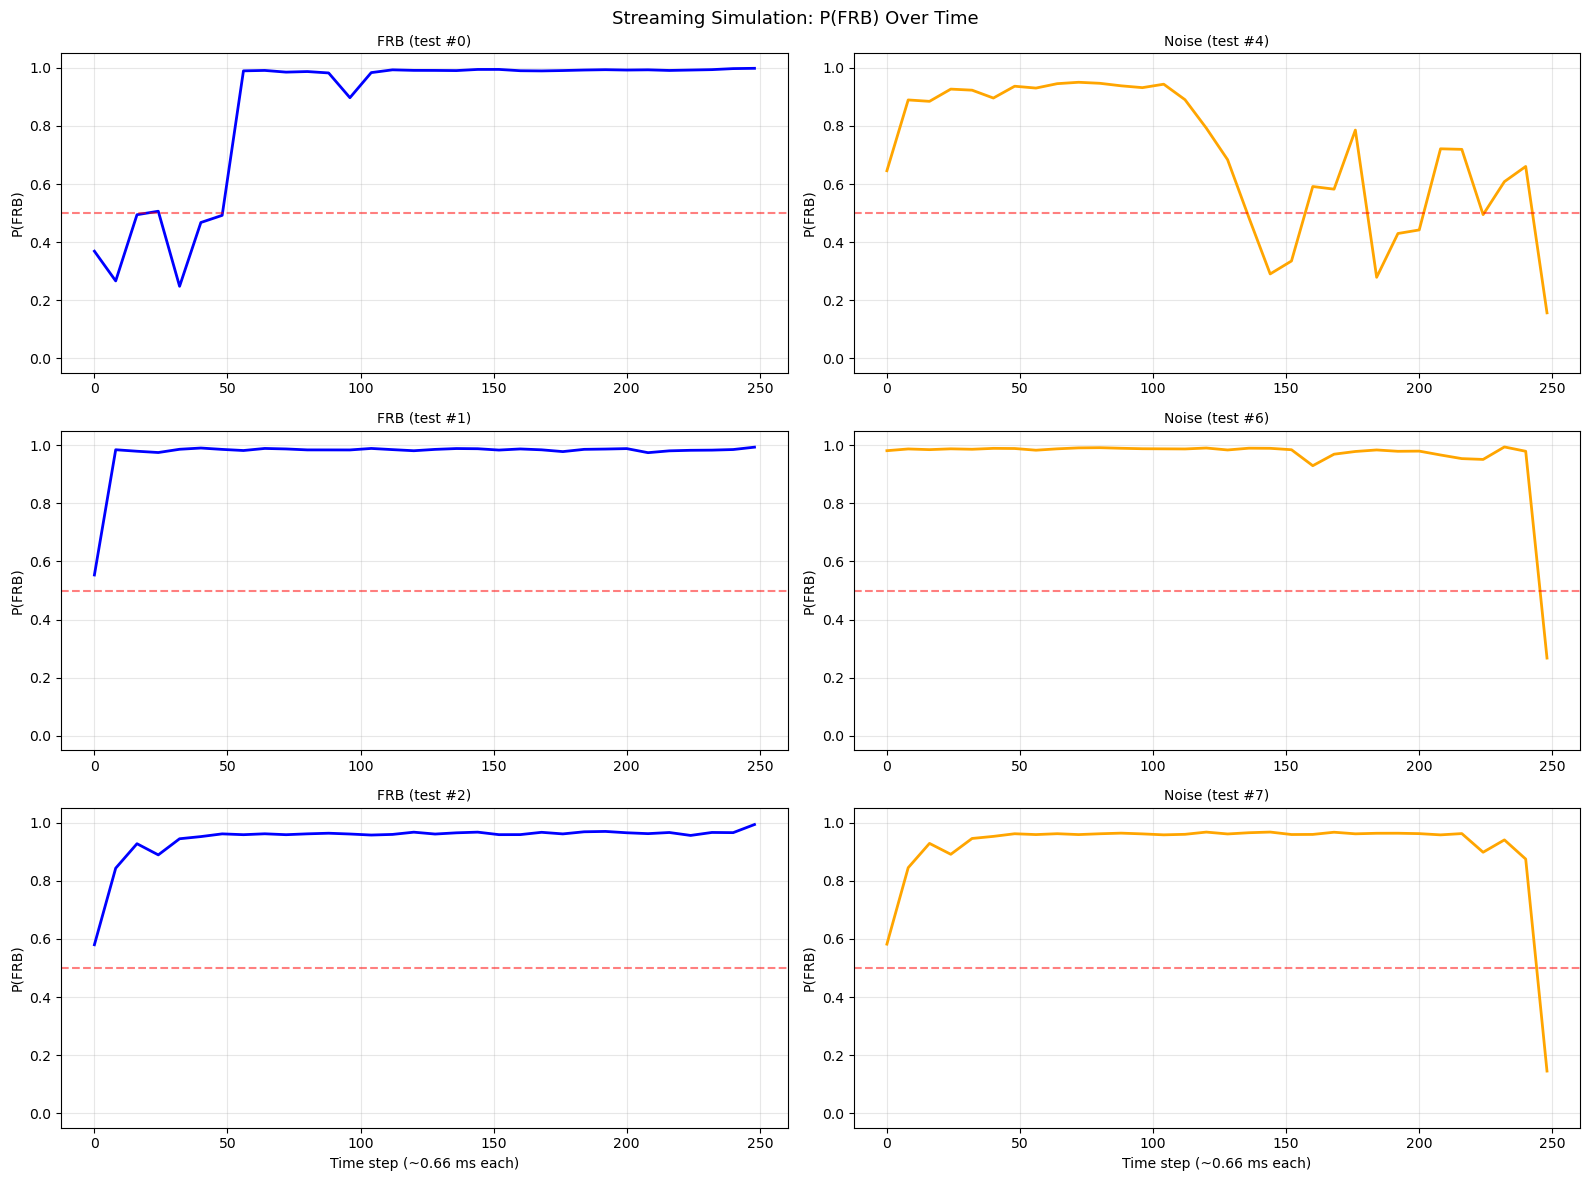

In [13]:
# Pick a few FRB and noise samples to simulate streaming
n_demo = 3
frb_indices = np.where(y_test == 1)[0][:n_demo]
noise_indices = np.where(y_test == 0)[0][:n_demo]

# Use coarser step for speed with return_sequences=False
step_size = 1 if CONFIG["return_sequences"] else 8

fig, axes = plt.subplots(n_demo, 2, figsize=(16, 4 * n_demo))
if n_demo == 1:
    axes = axes[np.newaxis, :]

for row in range(n_demo):
    # FRB sample
    idx_frb = frb_indices[row]
    probs_frb = streaming_prediction(model, X_test[idx_frb], step_size)
    
    time_axis_frb = np.arange(len(probs_frb)) * step_size
    axes[row, 0].plot(time_axis_frb, probs_frb, 'b-', linewidth=2)
    axes[row, 0].axhline(0.5, color='r', ls='--', alpha=0.5)
    axes[row, 0].set_ylim(-0.05, 1.05)
    axes[row, 0].set_title(f"FRB (test #{idx_frb})", fontsize=10)
    axes[row, 0].set_ylabel("P(FRB)")
    axes[row, 0].grid(True, alpha=0.3)
    
    # Noise sample
    idx_noise = noise_indices[row]
    probs_noise = streaming_prediction(model, X_test[idx_noise], step_size)
    
    time_axis_noise = np.arange(len(probs_noise)) * step_size
    axes[row, 1].plot(time_axis_noise, probs_noise, 'orange', linewidth=2)
    axes[row, 1].axhline(0.5, color='r', ls='--', alpha=0.5)
    axes[row, 1].set_ylim(-0.05, 1.05)
    axes[row, 1].set_title(f"Noise (test #{idx_noise})", fontsize=10)
    axes[row, 1].set_ylabel("P(FRB)")
    axes[row, 1].grid(True, alpha=0.3)

for ax in axes[-1, :]:
    ax.set_xlabel("Time step (~0.66 ms each)")

plt.suptitle("Streaming Simulation: P(FRB) Over Time", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Save Everything

In [14]:
# Save model in multiple formats
# Keras format (for reloading)
model.save(os.path.join(save_dir, "model.keras"))

# H5 format (for hls4ml compatibility)
model.save(os.path.join(save_dir, "model.h5"))

# Save config
config_save = CONFIG.copy()
config_save["total_params"] = int(total_params)
config_save["trainable_params"] = int(trainable_params)
config_save["best_epoch"] = int(best_epoch + 1)
config_save["best_val_loss"] = float(history.history["val_loss"][best_epoch])
config_save["best_val_acc"] = float(history.history["val_accuracy"][best_epoch])
config_save["test_loss"] = float(test_loss)
config_save["test_acc"] = float(test_acc)
config_save["roc_auc"] = float(roc_auc)
config_save["pr_auc"] = float(pr_auc)
config_save["timestamp"] = datetime.now().isoformat()
config_save["n_timesteps"] = int(n_timesteps)
config_save["n_features"] = int(n_features)

with open(os.path.join(save_dir, "config.json"), 'w') as f:
    json.dump(config_save, f, indent=2)

# Save training history
hist_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with open(os.path.join(save_dir, "history.json"), 'w') as f:
    json.dump(hist_dict, f, indent=2)

print(f"\nSaved to: {save_dir}/")
for fname in os.listdir(save_dir):
    fsize = os.path.getsize(os.path.join(save_dir, fname))
    print(f"  {fname} ({fsize/1024:.1f} KB)")


Saved to: ./models/lstm_v3/
  best_model.keras (389.4 KB)
  config.json (1.0 KB)
  evaluation.png (90.8 KB)
  history.json (18.9 KB)
  model.h5 (387.0 KB)
  model.keras (389.4 KB)
  training_curves.png (148.0 KB)


In [15]:
# ============================================================
# FINAL SUMMARY
# ============================================================
print("=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)
print(f"Experiment:        {CONFIG['experiment_name']}")
print(f"Model:             {CONFIG['model_type'].upper()}, {CONFIG['n_rnn_layers']} layer(s), "
      f"{CONFIG['rnn_units']} units")
print(f"Dense head:        {CONFIG['dense_units']}")
print(f"Parameters:        {total_params:,} "
      f"{'✅' if total_params < 50000 else '⚠️  over FPGA budget'}")
print(f"Input shape:       ({n_timesteps}, {n_features})")
print(f"Return sequences:  {CONFIG['return_sequences']}")
print(f"")
print(f"Best epoch:        {best_epoch + 1}/{len(history.history['loss'])}")
print(f"Val accuracy:      {history.history['val_accuracy'][best_epoch]:.4f}")
print(f"Test accuracy:     {test_acc:.4f}")
print(f"ROC AUC:           {roc_auc:.4f}")
print(f"PR AUC:            {pr_auc:.4f}")
print(f"")
print(f"Saved to:          {save_dir}/")
print(f"")
print(f"Next steps:")
print(f"  1. Check if accuracy is suspiciously high (>99%) — might be texture shortcut")
print(f"  2. Try different configs: rnn_units, n_rnn_layers, freq_reduction")
print(f"  3. If happy with performance → hls4ml synthesis")
print(f"")
print(f"Quick experiments to try:")
print(f"  - Smaller:  rnn_units=16, dense_units=[]")
print(f"  - Bigger:   rnn_units=64, dense_units=[64, 32]")
print(f"  - GRU:      model_type='gru' (fewer params than LSTM)")
print(f"  - Reduced:  freq_reduction=64 (compress 256 features to 64)")
print(f"  - Streaming: return_sequences=True (P(FRB) at every timestep)")

EXPERIMENT SUMMARY
Experiment:        lstm_v3
Model:             LSTM, 1 layer(s), 32 units
Dense head:        [32]
Parameters:        29,953 ✅
Input shape:       (256, 256)
Return sequences:  False

Best epoch:        145/150
Val accuracy:      0.9513
Test accuracy:     0.9643
ROC AUC:           0.9788
PR AUC:            0.9859

Saved to:          ./models/lstm_v3/

Next steps:
  1. Check if accuracy is suspiciously high (>99%) — might be texture shortcut
  2. Try different configs: rnn_units, n_rnn_layers, freq_reduction
  3. If happy with performance → hls4ml synthesis

Quick experiments to try:
  - Smaller:  rnn_units=16, dense_units=[]
  - Bigger:   rnn_units=64, dense_units=[64, 32]
  - GRU:      model_type='gru' (fewer params than LSTM)
  - Reduced:  freq_reduction=64 (compress 256 features to 64)
  - Streaming: return_sequences=True (P(FRB) at every timestep)
